=== Analytic expressions ===
Regime: underdamped (zeta < 1)

vC(t) =
⎛      100.0⋅t                                                                 ↪
⎝12.0⋅ℯ        - 1.60591013709393⋅sin(435.889894354067⋅t) - 7.0⋅cos(435.889894 ↪

↪          ⎞  -100.0⋅t
↪ 354067⋅t)⎠⋅ℯ        

i(t) =
                                                                               ↪
(0.321182027418786⋅sin(435.889894354067⋅t) + 2.77555756156289e-17⋅cos(435.8898 ↪

↪               -100.0⋅t
↪ 94354067⋅t))⋅ℯ        


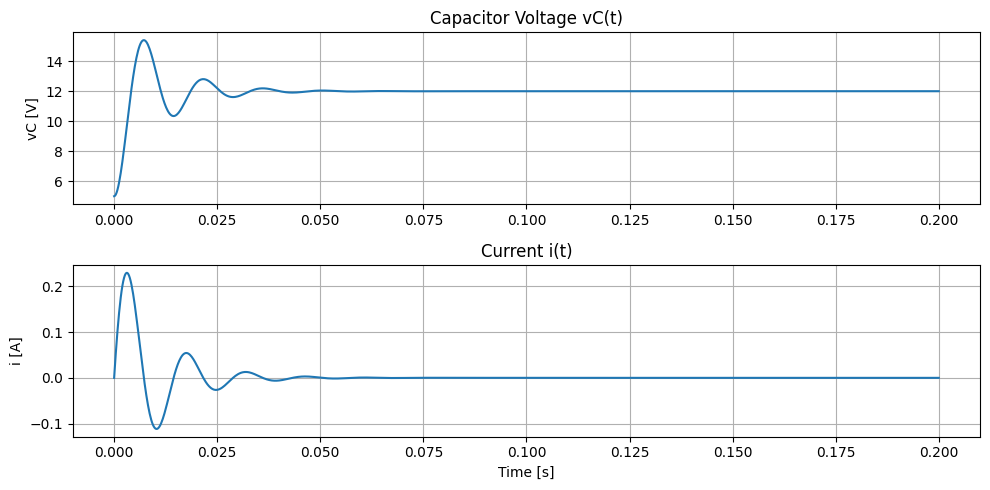

In [8]:
# RLC series with DC step at t=0, using initial capacitor voltage vC0
# All comments are in English.

import numpy as np
import matplotlib.pyplot as plt
from sympy import symbols, Function, Eq, dsolve, Heaviside, simplify, sqrt, lambdify, DiracDelta, pretty

t = symbols('t', real=True)
q = Function('q')

def solve_series_rlc_dc(R, L, C, Vs, vC0=0.0, i0=0.0, step_at_zero=True):
    # Differential equation: L*q'' + R*q' + (1/C)*q = Vs
    F = Vs * Heaviside(t) if step_at_zero else Vs
    ode = Eq(L*q(t).diff(t, 2) + R*q(t).diff(t) + (1/C)*q(t), F)

    # Convert capacitor voltage to initial charge
    q0 = C * vC0
    ics = {q(0): q0, q(t).diff(t).subs(t, 0): i0}

    # Solve
    sol_q = dsolve(ode, ics=ics)
    q_t = simplify(sol_q.rhs.subs(Heaviside(t), 1))
    i_t = simplify(q_t.diff(t))

    # Remove DiracDelta
    q_t = q_t.replace(lambda e: e.has(DiracDelta), lambda e: 0)
    i_t = i_t.replace(lambda e: e.has(DiracDelta), lambda e: 0)

    # Damping info
    alpha = R / (2*L)
    omega0 = 1 / sqrt(L*C)
    zeta = alpha / omega0
    regime = ("underdamped (zeta < 1)" if zeta.evalf() < 1
              else "critically damped (zeta = 1)" if abs(zeta.evalf() - 1) < 1e-9
              else "overdamped (zeta > 1)")

    # Capacitor voltage as function
    vC_t = simplify(q_t / C)

    return {"q(t)": q_t, "i(t)": i_t, "vC(t)": vC_t, "zeta": zeta, "regime": regime}

# ---- Example ----
R = 10.0       # ohms
L = 50e-3      # H
C = 100e-6     # F
Vs = 12.0      # V
vC0 = 5.0      # initial capacitor voltage [V]
i0 = 0.0       # initial current [A]

res = solve_series_rlc_dc(R, L, C, Vs, vC0=vC0, i0=i0, step_at_zero=True)

# Show analytic functions
print("=== Analytic expressions ===")
print("Regime:", res["regime"])
print("\nvC(t) =")
print(pretty(res["vC(t)"], use_unicode=True))
print("\ni(t) =")
print(pretty(res["i(t)"], use_unicode=True))

# Numeric functions
vC_func = lambdify(t, res["vC(t)"], 'numpy')
i_func = lambdify(t, res["i(t)"], 'numpy')

# Time axis
t_vals = np.linspace(0, 0.2, 1000)
vC_vals = vC_func(t_vals)
i_vals = i_func(t_vals)

# Plot
plt.figure(figsize=(10,5))
plt.subplot(2,1,1)
plt.plot(t_vals, vC_vals)
plt.title('Capacitor Voltage vC(t)')
plt.ylabel('vC [V]')
plt.grid(True)

plt.subplot(2,1,2)
plt.plot(t_vals, i_vals)
plt.title('Current i(t)')
plt.xlabel('Time [s]')
plt.ylabel('i [A]')
plt.grid(True)

plt.tight_layout()
plt.show()
